# 04 · Validación cruzada agrupada: estabilidad comparativa de las configuraciones

## Qué evalúa y qué no evalúa

**Evalúa estabilidad comparativa.** 
Pregunta: ¿las diferencias entre MLP A, MLP B, Ridge A y Ridge B se mantienen cuando cambia la partición de corredores?

**No es nested cross-validation.** 
Las configuraciones 840 y 1633 y los valores de alpha se seleccionaron con la **validación original** (notebooks 02, 03 y la Parte 1). Esta CV reutiliza esas elecciones tal como están. Por eso **no es una estimación completamente independiente de generalización**: sólo el test lo sería, y permanece reservado.

## Diseño

- **Datos:** sólo el **train original** (3597 carreras, 1514 corredores). La **validación original queda fuera** de esta CV. El test no se usa.
- **Folds:** `GroupKFold(5)` por `id`. Son los mismos para los cuatro modelos.
- **Semillas:** 300–304, iguales para A y B. La variabilidad entre semillas es sólo de inicialización; las semillas no son observaciones independientes.
- **Escalado, separado por etapa:**
  - *Early stopping:* el scaler se ajusta **sólo con el 85% de entrenamiento interno** y transforma ese entrenamiento y el 15% de validación interna.
  - *Reentrenamiento final:* se crea un scaler **nuevo**, ajustado con el **100% del entrenamiento del fold**.
  - *Ridge:* scaler ajustado con el 100% del entrenamiento del fold.
- **Validación interna para early stopping:** `GroupShuffleSplit` del 15% de los corredores del entrenamiento del fold. La semilla de partición es `42 + f`, fija por fold y compartida por A, B y todas las semillas.
- **MLP:** early stopping con paciencia 15 y máximo 200 épocas, registro de la mejor época `e*`, y reentrenamiento desde cero con `e* + 1` épocas fijas, sin escalar por el tamaño de los datos.
- **Ridge:** alpha fijo de la Parte 1 (A ≈ 1e-6, B = 100). Ajuste determinista, una vez por fold.
- **Ningún paso ajusta nada con el fold de evaluación.**

## 0. Configuración

In [2]:
import ast, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "processed" / "df_long.parquet").exists():
            return p
    raise FileNotFoundError("No se encontró data/processed/df_long.parquet")

ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
from common import (SEED, DEVICE, TARGET, FEATS_A, FEATS_B,
                    load_data, split_by_runner, train_mlp, predict, metrics)

RESULTS = ROOT / "resultados"
N_FOLDS = 5
SEEDS_CV = [300, 301, 302, 303, 304]
INNER_VAL = 0.15
ES = {"patience": 15, "max_epochs": 200}      # igual que en 03
CONFIG_A_ID, CONFIG_B_ID = 840, 1633          # seleccionadas con validación original
ALPHA = (pd.read_csv(RESULTS / "04_ridge_alpha_mejor.csv")
         .set_index("variante")["alpha"].astype(float).to_dict())   # seleccionadas con validación original
print(f"Raíz: .\nDevice: {DEVICE}\nalpha: {ALPHA}")

Raíz: .
Device: cpu
alpha: {'A': 1e-06, 'B': 100.0}


## 1. Configuraciones congeladas

Se leen de la etapa 1 de 03, sin reescribir los hiperparámetros a mano.

In [3]:
stage1 = pd.read_csv(RESULTS / "03_busqueda_etapa1.csv")

def config_from_stage1(variant, cid):
    r = stage1[(stage1.variante == variant) & (stage1.config_id == cid)].iloc[0]
    return dict(hidden=ast.literal_eval(r["hidden"]), lr=float(r["lr"]),
                dropout=float(r["dropout"]), weight_decay=float(r["weight_decay"]),
                batch_size=int(r["batch_size"]), optimizer=str(r["optimizer"]))

CFG = {"A": config_from_stage1("A", CONFIG_A_ID), "B": config_from_stage1("B", CONFIG_B_ID)}
for v in ["A", "B"]:
    print(f"MLP {v}:", CFG[v])

MLP A: {'hidden': (128,), 'lr': 0.003, 'dropout': 0.2, 'weight_decay': 0.001, 'batch_size': 32, 'optimizer': 'Adam'}
MLP B: {'hidden': (128, 64, 32), 'lr': 0.001, 'dropout': 0.2, 'weight_decay': 0.001, 'batch_size': 32, 'optimizer': 'AdamW'}


## 2. Datos y folds (sólo train original)

El test se separa con la misma partición de 02 y 03 y se descarta de inmediato. La validación original tampoco entra en la CV.

In [4]:
df = load_data(ROOT)
train, val, test = split_by_runner(df)
del test, val          # test reservado; validación fuera de la CV
train = train.reset_index(drop=True)
print(f"Train original: {len(train)} carreras, {train['id'].nunique()} corredores")

gkf = GroupKFold(n_splits=N_FOLDS)
train["fold"] = -1
for f, (_, ev_idx) in enumerate(gkf.split(train, groups=train["id"])):
    train.loc[train.index[ev_idx], "fold"] = f

assert (train["fold"] >= 0).all()
assert (train.groupby("id")["fold"].nunique() == 1).all(), "Un corredor en más de un fold"
fold_table = train.groupby("fold").agg(carreras=("id", "size"), corredores=("id", "nunique")).reset_index()
display(fold_table)
train[["id", "fold"]].drop_duplicates().to_csv(RESULTS / "04_cv_folds_train.csv", index=False)
print("Folds verificados: ningún corredor en dos folds.")

Train original: 3597 carreras, 1514 corredores


,fold,carreras,corredores
0,0,720,303
1,1,720,303
2,2,720,303
3,3,718,302
4,4,719,303


Folds verificados: ningún corredor en dos folds.


## 3. Procedimiento por fold

Para cada fold `f` (y para A y B):

1. **Ridge:** scaler ajustado con el 100% del entrenamiento del fold, alpha fijo, ajuste y predicción sobre el fold de evaluación.
2. **Validación interna:** 15% de los corredores del entrenamiento del fold, con semilla `42 + f`.
3. **Early stopping (semilla `s`):** scaler ajustado **sólo con el 85% de entrenamiento interno**. Transforma ese entrenamiento y la validación interna. Se registra la mejor época `e*`.
4. **Reentrenamiento (semilla `s`):** scaler **nuevo** ajustado con el **100% del entrenamiento del fold**. Entrenamiento desde cero con `e* + 1` épocas fijas, sin early stopping. Predicción sobre el fold de evaluación.

En el reentrenamiento, el argumento de validación de `train_mlp` recibe la validación interna, no el fold de evaluación. Sin early stopping, ese argumento sólo sirve para el registro de curvas.

In [5]:
def run_fold(f):
    tr_f = train[train.fold != f]
    ev_f = train[train.fold == f]
    rows, epoch_rows = [], []

    # Ridge: scaler con el 100% del entrenamiento del fold
    for v, feats in [("A", FEATS_A), ("B", FEATS_B)]:
        sc = StandardScaler().fit(tr_f[feats])
        r = Ridge(alpha=ALPHA[v]).fit(sc.transform(tr_f[feats]), tr_f[TARGET].values)
        rows.append({"modelo": f"Ridge {v}", "fold": f, "semilla": None,
                     "n_train": len(tr_f), "n_eval": len(ev_f),
                     **metrics(ev_f[TARGET].values, r.predict(sc.transform(ev_f[feats])))})

    # Validación interna (partición fija por fold)
    gss = GroupShuffleSplit(n_splits=1, test_size=INNER_VAL, random_state=SEED + f)
    a, b = next(gss.split(tr_f, groups=tr_f["id"]))
    in_tr, in_va = tr_f.iloc[a], tr_f.iloc[b]
    assert not (set(in_tr["id"]) & set(in_va["id"]))

    for v, feats in [("A", FEATS_A), ("B", FEATS_B)]:
        # Scaler para early stopping: sólo 85% de entrenamiento interno
        sc_es = StandardScaler().fit(in_tr[feats])
        Xi_tr, Xi_va = sc_es.transform(in_tr[feats]), sc_es.transform(in_va[feats])

        # Scaler para reentrenamiento: 100% del entrenamiento del fold
        sc_fin = StandardScaler().fit(tr_f[feats])
        X_full = sc_fin.transform(tr_f[feats])
        X_ev = sc_fin.transform(ev_f[feats])
        X_iva_fin = sc_fin.transform(in_va[feats])   # sólo para registro de curvas

        for seed in SEEDS_CV:
            # 1) Early stopping con el scaler de la etapa 1
            _, hist_es, e_star = train_mlp(Xi_tr, in_tr[TARGET].values, Xi_va, in_va[TARGET].values,
                                           seed=seed, early_stopping=ES, **CFG[v])
            n_ep = e_star + 1

            # 2) Reentrenamiento desde cero, 100% del entrenamiento del fold, n_ep fijas
            m, hist_fin, _ = train_mlp(X_full, tr_f[TARGET].values, X_iva_fin, in_va[TARGET].values,
                                       seed=seed, epochs=n_ep, early_stopping=None, **CFG[v])
            rows.append({"modelo": f"MLP {v}", "fold": f, "semilla": seed,
                         "n_train": len(tr_f), "n_eval": len(ev_f),
                         "mejor_epoca_es": e_star, "epocas_finales": n_ep,
                         "train_mse_final": hist_fin["train"][-1],
                         **metrics(ev_f[TARGET].values, predict(m, X_ev))})
            epoch_rows.append({"modelo": f"MLP {v}", "fold": f, "semilla": seed,
                               "mejor_epoca_es": e_star, "epocas_finales": n_ep,
                               "epocas_es_ejecutadas": len(hist_es["val"])})
    return rows, epoch_rows

print("Función lista.")

Función lista.


## 4. Ejecución

In [6]:
t0 = time.time()
all_rows, all_epochs = [], []
for f in range(N_FOLDS):
    r, e = run_fold(f)
    all_rows += r
    all_epochs += e
    print(f"fold {f} listo ({(time.time() - t0) / 60:.1f} min)")

cv_detail = pd.DataFrame(all_rows)
cv_epochs = pd.DataFrame(all_epochs)
cv_detail.round(6).to_csv(RESULTS / "04_cv_metricas_detalle.csv", index=False)
cv_epochs.to_csv(RESULTS / "04_cv_epocas.csv", index=False)
display(cv_detail.head(6).round(4))

fold 0 listo (0.5 min)
fold 1 listo (0.8 min)
fold 2 listo (1.3 min)
fold 3 listo (1.8 min)
fold 4 listo (2.3 min)


,modelo,fold,semilla,n_train,n_eval,RMSE,MAE,R2,mejor_epoca_es,epocas_finales,train_mse_final
0,Ridge A,0,NaN,2877,720,1.8155,1.4206,0.5369,NaN,NaN,NaN
1,Ridge B,0,NaN,2877,720,1.3904,1.0761,0.7284,NaN,NaN,NaN
2,MLP A,0,300.0,2877,720,1.7620,1.4005,0.5637,40.0,41.0,3.9383
3,MLP A,0,301.0,2877,720,1.7220,1.3700,0.5834,38.0,39.0,3.8827
4,MLP A,0,302.0,2877,720,1.7225,1.3643,0.5831,31.0,32.0,3.9690
5,MLP A,0,303.0,2877,720,1.7544,1.3944,0.5675,26.0,27.0,3.9557


## 5. Métricas por fold y resumen

In [7]:
mlp = cv_detail[cv_detail.modelo.str.startswith("MLP")]
ridge = cv_detail[cv_detail.modelo.str.startswith("Ridge")]

# Por fold: MLP promedia sobre semillas; Ridge es único por fold
per_fold_mlp = (mlp.groupby(["modelo", "fold"])[["RMSE", "MAE", "R2"]].mean().reset_index())
per_fold_mlp_sd = (mlp.groupby(["modelo", "fold"])[["RMSE", "MAE", "R2"]].std().reset_index())
per_fold_ridge = ridge.rename(columns={"modelo": "modelo"})[["modelo", "fold", "RMSE", "MAE", "R2"]]
per_fold = pd.concat([per_fold_mlp, per_fold_ridge], ignore_index=True)
per_fold.round(4).to_csv(RESULTS / "04_cv_metricas_por_fold.csv", index=False)

# Variabilidad entre semillas dentro de cada fold (sólo MLP)
seed_sd = per_fold_mlp_sd.rename(columns={c: f"{c}_sd_semillas" for c in ["RMSE", "MAE", "R2"]})
seed_sd.round(5).to_csv(RESULTS / "04_cv_variabilidad_semillas.csv", index=False)

# Resumen: media y sd entre folds (unidad de inferencia)
summary = per_fold.groupby("modelo")[["RMSE", "MAE", "R2"]].agg(["mean", "std"]).round(4)
summary.to_csv(RESULTS / "04_cv_resumen.csv")
display(summary)

print("\nRMSE por fold (promedio sobre semillas para MLP):")
display(per_fold.pivot(index="fold", columns="modelo", values="RMSE").round(4))

RMSE             MAE              R2        
           mean     std    mean     std    mean     std
modelo                                                 
MLP A    1.8563  0.0948  1.4511  0.0754  0.4632  0.0674
MLP B    1.4764  0.0598  1.1310  0.0401  0.6616  0.0247
Ridge A  1.8874  0.0937  1.4774  0.0757  0.4462  0.0599
Ridge B  1.4295  0.0682  1.0976  0.0434  0.6824  0.0339


RMSE por fold (promedio sobre semillas para MLP):


modelo,MLP A,MLP B,Ridge A,Ridge B
fold,,,,
0,1.7407,1.4592,1.8155,1.3904
1,1.9440,1.5669,2.0086,1.5509
2,1.8632,1.4199,1.8728,1.3981
3,1.7814,1.4328,1.7850,1.3980
4,1.9523,1.5030,1.9551,1.4099


## 6. Diferencias por fold

- **B − A (MLP):** negativo = B mejor. Diferencia pareada por fold (misma partición, mismas semillas, promedio sobre semillas).
- **MLP − Ridge (por variante):** negativo = la MLP es mejor.

La unidad de inferencia es el fold (n = 5). Los folds comparten datos de entrenamiento, y las semillas no son independientes.

In [8]:
def fold_diffs(a, b, label, src):
    pa = src[src.modelo == a].set_index("fold")
    pb = src[src.modelo == b].set_index("fold")
    out = []
    for metric in ["RMSE", "MAE", "R2"]:
        d = pb[metric] - pa[metric]
        t, p = stats.ttest_1samp(d.values, 0.0)
        out.append({"comparación": label, "métrica": metric,
                    "media_por_fold": d.mean(), "sd_entre_folds": d.std(ddof=1),
                    "folds_con_signo_negativo": int((d < 0).sum()), "n_folds": len(d),
                    "t_orientativa": t, "p_orientativo": p})
    return out

diffs = []
diffs += fold_diffs("MLP A", "MLP B", "B − A", per_fold)
diffs += fold_diffs("Ridge A", "MLP A", "MLP A − Ridge A", per_fold)
diffs += fold_diffs("Ridge B", "MLP B", "MLP B − Ridge B", per_fold)
diffs_df = pd.DataFrame(diffs)
diffs_df.round(4).to_csv(RESULTS / "04_cv_diferencias.csv", index=False)
display(diffs_df.round(4))

# Diferencias por semilla (descriptivas)
seed_piv = mlp.pivot_table(index=["fold", "semilla"], columns="modelo", values="RMSE").reset_index()
seed_piv["B_menos_A_RMSE"] = seed_piv["MLP B"] - seed_piv["MLP A"]
seed_piv.round(5).to_csv(RESULTS / "04_cv_diferencias_por_semilla.csv", index=False)
print(f"B − A por semilla: media {seed_piv.B_menos_A_RMSE.mean():.4f}, "
      f"sd {seed_piv.B_menos_A_RMSE.std():.4f}, negativas {int((seed_piv.B_menos_A_RMSE<0).sum())}/{len(seed_piv)}")

,comparación,métrica,media_por_fold,sd_entre_folds,folds_con_signo_negativo,n_folds,t_orientativa,p_orientativo
0,B − A,RMSE,-0.3800,0.0699,5,5,-12.1610,0.0003
1,B − A,MAE,-0.3201,0.0650,5,5,-11.0112,0.0004
2,B − A,R2,0.1984,0.0481,0,5,9.2284,0.0008
3,MLP A − Ridge A,RMSE,-0.0311,0.0355,5,5,-1.9552,0.1222
4,MLP A − Ridge A,MAE,-0.0263,0.0222,5,5,-2.6520,0.0569
5,MLP A − Ridge A,R2,0.0170,0.0190,0,5,2.0072,0.1152
6,MLP B − Ridge B,RMSE,0.0469,0.0329,0,5,3.1853,0.0334
7,MLP B − Ridge B,MAE,0.0334,0.0254,0,5,2.9427,0.0423
8,MLP B − Ridge B,R2,-0.0208,0.0138,5,5,-3.3717,0.0280


B − A por semilla: media -0.3800, sd 0.0789, negativas 25/25


## 7. Épocas de early stopping y reentrenamiento

In [9]:
ep_summary = cv_epochs.groupby(["modelo", "fold"])["mejor_epoca_es"].agg(["mean", "std", "min", "max"]).round(2)
display(ep_summary)
ep_summary.to_csv(RESULTS / "04_cv_epocas_resumen.csv")

mean    std  min  max
modelo fold                       
MLP A  0     34.6   5.90   26   40
       1     25.8   7.40   17   34
       2     42.8  15.87   28   61
       3     32.2  10.33   19   44
       4     36.4   8.62   28   49
MLP B  0     44.2  15.19   28   61
       1     31.6  11.01   24   51
       2     51.4  12.66   31   65
       3     50.2  12.11   35   64
       4     45.4  21.31   27   79

## 8. Gráficas

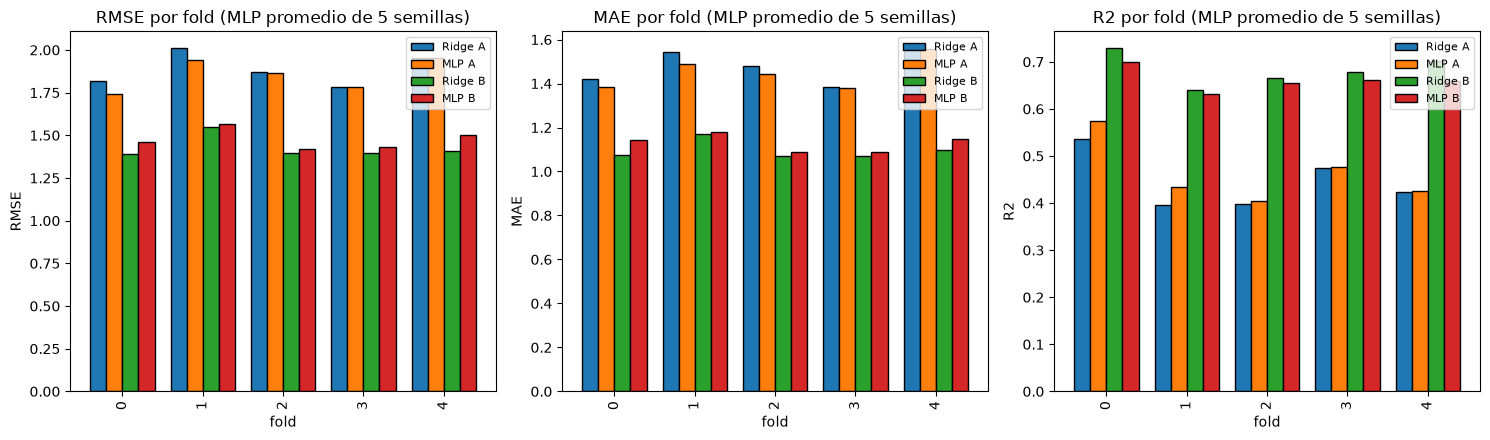

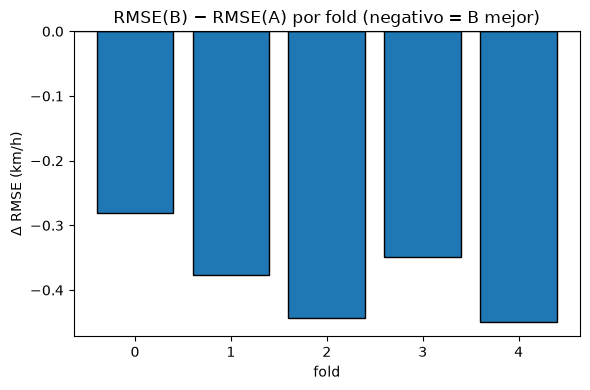

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    piv = per_fold.pivot(index="fold", columns="modelo", values=metric)
    piv[["Ridge A", "MLP A", "Ridge B", "MLP B"]].plot(kind="bar", ax=ax, edgecolor="black", width=0.8)
    ax.set_title(f"{metric} por fold (MLP promedio de 5 semillas)")
    ax.set_xlabel("fold"); ax.set_ylabel(metric); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

piv = per_fold.pivot(index="fold", columns="modelo", values="RMSE")
d_ba = piv["MLP B"] - piv["MLP A"]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(d_ba.index.astype(str), d_ba.values, edgecolor="black")
ax.axhline(0, color="black", lw=1)
ax.set_title("RMSE(B) − RMSE(A) por fold (negativo = B mejor)")
ax.set_xlabel("fold"); ax.set_ylabel("Δ RMSE (km/h)")
plt.tight_layout(); plt.show()

## Conclusiones 

Configuraciones y alphas fueron seleccionados con la validación original. Esta CV usa sólo el train original, con 5 folds agrupados por corredor y 5 semillas por fold. Las semillas describen variabilidad de inicialización, los folds son la unidad de inferencia (n = 5). Los p-valores son orientativos.

### 1. Aporte de las variables de entrenamiento (B − A)
- RMSE medio por fold: B − A = −0.377 km/h (sd entre folds 0.066). B es mejor en los 5 folds y en las 25 corridas (semillas × folds).
- Este resultado es **consistente** en esta CV y coincide en dirección y magnitud con 02 (−0.44) y 03 (−0.44).

### 2. MLP vs Ridge, cada variante contra su Ridge
- **A:** MLP A − Ridge A = −0.033 km/h (sd 0.034). La MLP es mejor en 5/5 folds. Dirección consistente con 03, pero la diferencia es pequeña y el alpha de Ridge A es prácticamente OLS.
- **B:** MLP B − Ridge B = +0.048 km/h (sd 0.034). Ridge B es mejor en 5/5 folds. Esto contradice el empate observado en 03 (confirmación: 1.458 vs 1.460). Con esta partición, MLP B no supera a Ridge B.
- No hay una arquitectura superior per se, el resultado depende de la partición y de los datos de entrenamiento de cada fold.

### 3. Hipótesis que la CV no permite distinguir
- La peor posición de MLP B puede venir del procedimiento de reentrenamiento: épocas estimadas con early stopping sobre el 15% de corredores, y el escalado separado por etapa. Las épocas de MLP B varían bastante entre folds (medias 32–51, máximos hasta 79). Esta CV no tiene una comparación con early stopping sobre el fold de evaluación, así que no puedo separar el efecto del modelo y el del procedimiento. Es la siguiente verificación recomendada.

### 4. Variabilidad entre inicializaciones
- sd media entre semillas dentro de cada fold: MLP A 0.022 km/h, MLP B 0.041 km/h. Es pequeña frente a la diferencia B − A y comparable a las diferencias MLP − Ridge.

### 5. Limitaciones que condicionan estas conclusiones
- Las configuraciones y alphas se seleccionaron con validación original, y esa selección tuvo más presión sobre la MLP (150 configuraciones) que sobre Ridge (41 alphas con curva plana). El sesgo no se corrige aquí.
- Cinco folds de ~300 corredores; los entrenamientos se solapan. Las pruebas t son orientativas.
- Todos los corredores tienen dos o más carreras; la dependencia dentro de corredor sigue presente en cada fold.
- La variabilidad por partición interna de early stopping no está incluida.
- El test permanece reservado y no se usó.

### Síntesis
- **Evidencia consistente:** las variables de entrenamiento mejoran la predicción de forma consistente en esta CV (B − A).
- **Evidencia consistente pero pequeña:** MLP A supera a Ridge A.
- **Resultado inconcluso:** MLP B supera a Ridge B en validación original (empate) pero no en CV, la diferencia entre particiones no está resuelta.